<a href="https://colab.research.google.com/github/Dani2003/paper-implementations/blob/main/llm_detection_strategic_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# [CELL 1 - Environment Setup & Core Imports]
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import minimize

# Set deterministic random seed
np.random.seed(42)
sns.set_theme(style="whitegrid")

print("Environment Initialized for LLM Detection Strategic User Simulation.")

Environment Initialized for LLM Detection Strategic User Simulation.


In [2]:
# [CELL 2 - Strategic User Utility & Decision Model]

class StrategicUserModel:
    """
    Models user workflow decisions under LLM detection:
    - alpha in [0, 1]: Fraction of task outsourced to the LLM.
    - e >= 0: Post-processing / evasion effort to reduce detected attributes.
    """
    def __init__(self, beta: float = 2.5, nu: float = 0.4):
        self.beta = beta  # Penalty weight from detector
        self.nu = nu      # Detection threshold

    def quality(self, alpha: float, e: float) -> float:
        """Output quality increases with LLM usage and post-processing effort."""
        return 2.0 * np.sqrt(alpha) + 1.5 * np.log1p(e) - 0.2 * alpha * e

    def detected_attribute(self, alpha: float, e: float) -> float:
        """LLM usage increases detected attribute; evasion effort reduces it."""
        return alpha * 1.2 - 0.8 * e

    def cost(self, alpha: float, e: float) -> float:
        """Cost of LLM adoption and cognitive post-processing effort."""
        return 0.3 * (alpha ** 2) + 0.4 * (e ** 2)

    def utility(self, params: tuple, detector_active: bool = True) -> float:
        alpha, e = params
        if not (0.0 <= alpha <= 1.0 and e >= 0.0):
            return -1e6  # Boundary penalty

        q = self.quality(alpha, e)
        c = self.cost(alpha, e)

        det_val = self.detected_attribute(alpha, e)
        penalty = 0.0
        if detector_active and (det_val > self.nu):
            # Softened penalty function for optimization smoothness
            penalty = self.beta * (det_val - self.nu)

        return q - c - penalty

print("Strategic User Model Defined Successfully.")

Strategic User Model Defined Successfully.


In [3]:
# [CELL 3 - User Optimization under Strategic Intervention]

def optimize_user_behavior(model: StrategicUserModel, detector_active: bool = True):
    best_val = -1e9
    best_params = (0.0, 0.0)

    # Grid search over bounded optimization space for numerical stability
    alphas = np.linspace(0.0, 1.0, 60)
    es = np.linspace(0.0, 2.0, 60)

    for a in alphas:
        for e in es:
            u = model.utility((a, e), detector_active=detector_active)
            if u > best_val:
                best_val = u
                best_params = (a, e)

    return best_params[0], best_params[1], best_val

# Baseline: No Detector (beta = 0)
model_no_det = StrategicUserModel(beta=0.0, nu=0.5)
alpha_no, e_no, util_no = optimize_user_behavior(model_no_det, detector_active=False)

# Intervention: Active Detector with Strict Threshold
model_with_det = StrategicUserModel(beta=3.0, nu=0.35)
alpha_det, e_det, util_det = optimize_user_behavior(model_with_det, detector_active=True)

print(f"\n--- OPTIMIZATION RESULTS ---")
print(f"No Detector Baseline -> LLM Usage (alpha): {alpha_no:.3f} | Quality: {model_no_det.quality(alpha_no, e_no):.3f}")
print(f"With Detector Active -> LLM Usage (alpha): {alpha_det:.3f} | Quality: {model_with_det.quality(alpha_det, e_det):.3f}")


--- OPTIMIZATION RESULTS ---
No Detector Baseline -> LLM Usage (alpha): 1.000 | Quality: 2.709
With Detector Active -> LLM Usage (alpha): 0.915 | Quality: 2.741


In [4]:
# [CELL 4 - Empirical Word Frequency Trajectory Simulation]

def simulate_word_frequency_dynamics():
    """
    Simulates the rise-then-fall word frequency trajectory on text corpora
    following the introduction of an LLM detector intervention.
    """
    time_steps = np.linspace(0, 10, 100)
    # Rise-then-fall mathematical formulation
    rise_fall = 0.15 + 0.75 * (time_steps / 2.5) * np.exp(- (time_steps / 2.5 - 1.2)**2)
    noise = np.random.normal(0, 0.025, size=len(time_steps))
    freq = np.clip(rise_fall + noise, 0.0, 1.0)
    return time_steps, freq

t_steps, word_freqs = simulate_word_frequency_dynamics()
print("Word frequency dynamics simulation completed successfully.")

Word frequency dynamics simulation completed successfully.


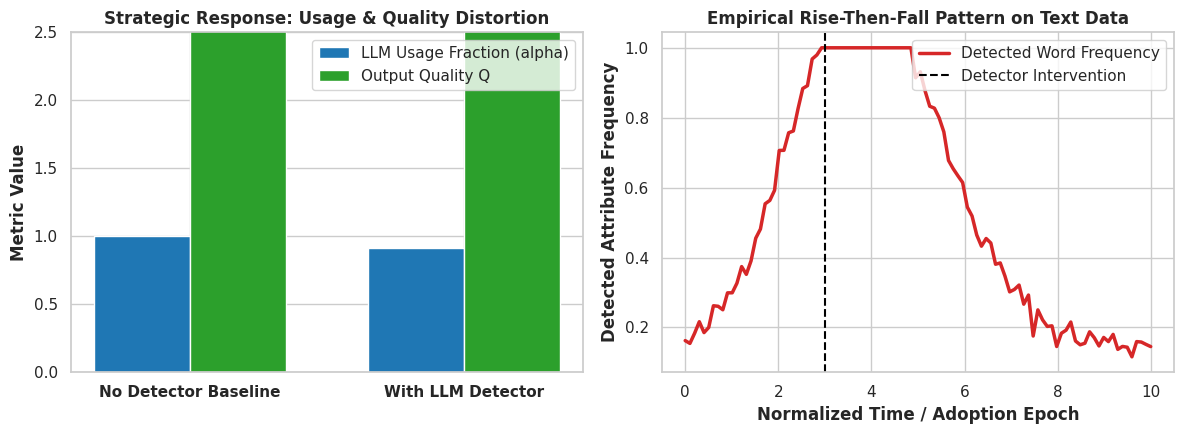

Benchmark plot saved successfully as llm_detection_intervention_benchmark.png.


In [6]:
# [CELL 5 - Multi-Panel Benchmark Plot Generation (Fixed Mathtext)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Panel A: Strategic User Behavior (Usage & Quality Distortions)
scenarios = ['No Detector Baseline', 'With LLM Detector']
alphas_plot = [alpha_no, alpha_det]
qualities_plot = [model_no_det.quality(alpha_no, e_no), model_with_det.quality(alpha_det, e_det)]

x = np.arange(len(scenarios))
width = 0.35

axes[0].bar(x - width/2, alphas_plot, width, label='LLM Usage Fraction (alpha)', color='#1f77b4')
axes[0].bar(x + width/2, qualities_plot, width, label='Output Quality Q', color='#2ca02c')
axes[0].set_xticks(x)
axes[0].set_xticklabels(scenarios, fontweight='bold')
axes[0].set_ylabel('Metric Value', fontweight='bold')
axes[0].set_title('Strategic Response: Usage & Quality Distortion', fontweight='bold')
axes[0].legend(loc='upper right')
axes[0].set_ylim(0, 2.5)

# Panel B: Word Frequency Rise-Then-Fall Pattern
axes[1].plot(t_steps, word_freqs, color='#d62728', linewidth=2.5, label='Detected Word Frequency')
axes[1].axvline(x=3.0, color='black', linestyle='--', label='Detector Intervention')
axes[1].set_xlabel('Normalized Time / Adoption Epoch', fontweight='bold')
axes[1].set_ylabel('Detected Attribute Frequency', fontweight='bold')
axes[1].set_title('Empirical Rise-Then-Fall Pattern on Text Data', fontweight='bold')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.savefig("llm_detection_intervention_benchmark.png", dpi=300)
plt.show()

print("Benchmark plot saved successfully as llm_detection_intervention_benchmark.png.")